# 1. Analyse exploratoire et préparation des données

Chargement des données, périmètre (bâtiments non résidentiels), nettoyage, étude de la cible, feature engineering et transformations. Tout le nettoyage est fait ici, les notebooks de modélisation n'ont plus qu'à séparer X et y.

**Sortie :** `data/batiments_cible.csv`, avec les deux cibles : la consommation (notebook 2) et les émissions de CO2 (notebook 3).

### Import des modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

### Analyse Exploratoire

In [2]:
building_consumption = pd.read_csv("data/2016_Building_Energy_Benchmarking.csv")

In [3]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [5]:
building_consumption["BuildingType"].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [6]:
building_consumption["PrimaryPropertyType"].value_counts()

PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      25
Residence Hall                  23
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Office                           3
Name: count, dtype: int64

In [7]:
n_avant = len(building_consumption)
df = building_consumption[~building_consumption["BuildingType"].str.contains("Multifamily")]

In [8]:
print(f"{n_avant} -> {len(df)} bâtiments ({n_avant - len(df)} retirés)")

3376 -> 1668 bâtiments (1708 retirés)


In [9]:
# % de cases vides par colonne, du plus vide au moins vide
manquants = df.isna().mean().sort_values(ascending=False) * 100
manquants[manquants > 0].round(1)

Comments                           100.0
Outlier                             99.0
YearsENERGYSTARCertified            94.1
ThirdLargestPropertyUseType         78.8
ThirdLargestPropertyUseTypeGFA      78.8
SecondLargestPropertyUseType        48.7
SecondLargestPropertyUseTypeGFA     48.7
ENERGYSTARScore                     34.4
ZipCode                              1.0
LargestPropertyUseType               0.4
LargestPropertyUseTypeGFA            0.4
SiteEUI(kBtu/sf)                     0.2
SiteEUIWN(kBtu/sf)                   0.2
SiteEnergyUseWN(kBtu)                0.2
Electricity(kBtu)                    0.1
Electricity(kWh)                     0.1
NaturalGas(kBtu)                     0.1
NaturalGas(therms)                   0.1
GHGEmissionsIntensity                0.1
SteamUse(kBtu)                       0.1
SourceEUIWN(kBtu/sf)                 0.1
SourceEUI(kBtu/sf)                   0.1
TotalGHGEmissions                    0.1
NumberofBuildings                    0.1
ListOfAllPropert

In [10]:
n_avant = len(df)

# 1. On ne garde que les relevés jugés fiables par la ville
df = df[df["ComplianceStatus"] == "Compliant"]

# 2. Un bâtiment sans 2e/3e usage = 0 m² pour cet usage
for col in ["SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]:
    df[col] = df[col].fillna(0)

print(f"{n_avant} -> {len(df)} bâtiments")

1668 -> 1548 bâtiments


In [11]:
# vérif : il ne reste plus de bâtiments signalés Outlier ou avec des données par défaut
print(df["Outlier"].value_counts(dropna=False))
print(df["DefaultData"].value_counts())

Outlier
NaN    1548
Name: count, dtype: int64
DefaultData
False    1548
Name: count, dtype: int64


In [12]:
# Colonnes retirées, rangées par raison
a_supprimer = [
    # 1. Identifiants et adresse : ils désignent un bâtiment sans rien dire de sa consommation
    "OSEBuildingID", "DataYear", "PropertyName", "Address", "City", "State",
    "ZipCode", "TaxParcelIdentificationNumber", "CouncilDistrictCode",
    # 2. Vides ou sans information utile
    "Comments", "YearsENERGYSTARCertified", "Outlier", "ListOfAllPropertyUseTypes",
    "ComplianceStatus", "DefaultData",
    # 3. Déjà utilisées ou peu utiles (retour mentor) : BuildingType a servi au filtre du début
    "BuildingType", "Latitude", "Longitude",
    # 4. Fuite de données : ces valeurs ne sont connues qu'après avoir mesuré la consommation
    "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)", "SourceEUI(kBtu/sf)",
    "SourceEUIWN(kBtu/sf)", "SiteEnergyUseWN(kBtu)", "GHGEmissionsIntensity",
]
# Gardées pour le feature engineering : ENERGYSTARScore, SteamUse, Electricity, NaturalGas

df = df.drop(columns=a_supprimer)
print(df.shape)
df.columns

(1548, 22)


Index(['PrimaryPropertyType', 'Neighborhood', 'YearBuilt', 'NumberofBuildings',
       'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking',
       'PropertyGFABuilding(s)', 'LargestPropertyUseType',
       'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType',
       'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore',
       'SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kWh)',
       'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)',
       'TotalGHGEmissions'],
      dtype='str')

#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

### Choix de la cible et distribution

count    1.548000e+03
mean     8.860058e+06
std      3.130568e+07
min      5.713320e+04
25%      1.251083e+06
50%      2.732167e+06
75%      7.294487e+06
max      8.739237e+08
Name: SiteEnergyUse(kBtu), dtype: float64


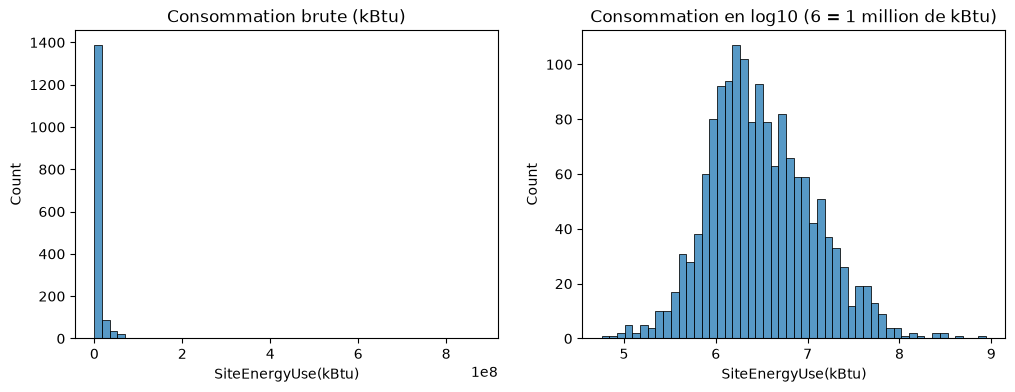

In [13]:
# Cible retenue : la consommation d'énergie totale du bâtiment
cible = "SiteEnergyUse(kBtu)"

# TotalGHGEmissions est gardée : ce sera la cible du notebook 3 (CO2).
# Elle découle de la consommation, donc elle ne doit jamais servir de feature pour prédire la conso.

print(df[cible].describe())

# Distribution brute, puis en log10 (≈ nombre de zéros de la consommation)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[cible], bins=50, ax=axes[0])
axes[0].set_title("Consommation brute (kBtu)")
sns.histplot(np.log10(df[cible]), bins=50, ax=axes[1])
axes[1].set_title("Consommation en log10 (6 = 1 million de kBtu)")
plt.show()

### Cible et type de bâtiment

A réaliser : boxplots de la cible par `PrimaryPropertyType`, repérer les valeurs aberrantes, retirer les bâtiments incohérents (0 étage, 0 bâtiment).

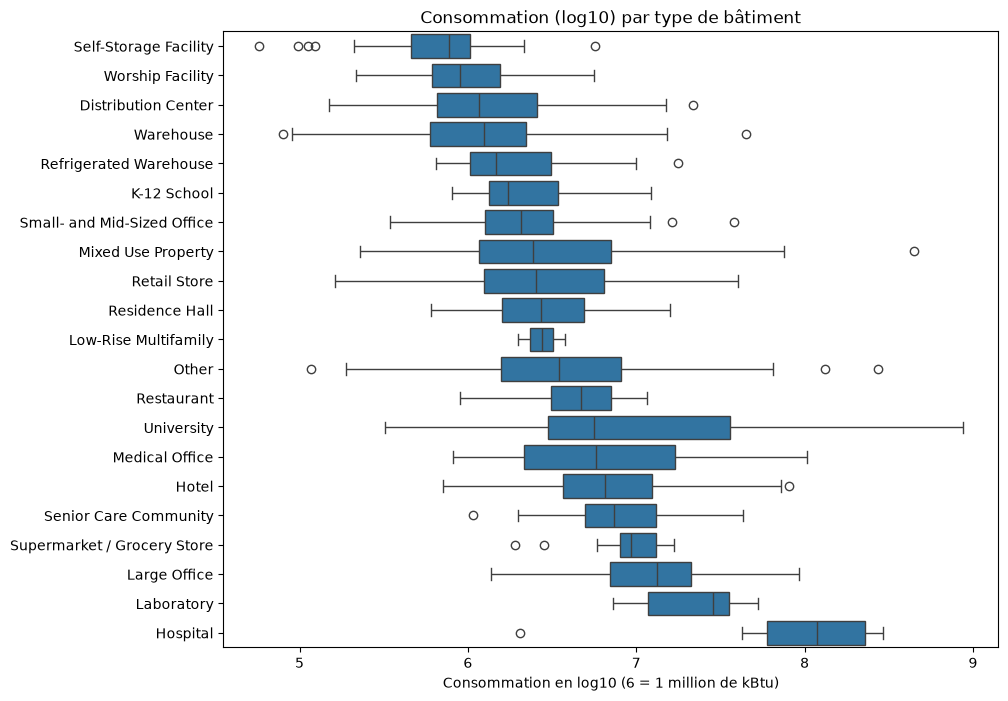

In [14]:
# Boxplots de la conso (en log10) par type de bâtiment
# je classe les types par médiane pour que le graphique soit plus facile à lire
df["log_conso"] = np.log10(df[cible])
ordre = df.groupby("PrimaryPropertyType")["log_conso"].median().sort_values().index

plt.figure(figsize=(10, 8))
sns.boxplot(data=df, x="log_conso", y="PrimaryPropertyType", order=ordre)
plt.title("Consommation (log10) par type de bâtiment")
plt.xlabel("Consommation en log10 (6 = 1 million de kBtu)")
plt.ylabel("")
plt.show()

# colonne juste pour le graphique, je la retire sinon elle part dans le CSV (= la réponse !)
df = df.drop(columns=["log_conso"])

Les hôpitaux sont ceux qui consomment le plus (médiane autour de 8,1 en log, soit environ 120 millions de kBtu). C'est logique, ils tournent 24h/24 avec beaucoup de matériel. À l'opposé, les garde-meubles consomment le moins (médiane autour de 5,9, environ 780 000 kBtu) : peu de chauffage et presque personne dedans. Il y a à peu près 2 unités d'écart en log, donc un hôpital consomme 100 à 150 fois plus qu'un garde-meuble.

Le type de bâtiment devrait donc beaucoup aider le modèle, et on le connaît sans avoir besoin de mesurer quoi que ce soit.

### Bâtiments incohérents

Certaines fiches sont impossibles : 0 bâtiment ou 0 étage alors que le bâtiment a une surface et consomme. On ne connaît pas la vraie valeur, donc je les retire plutôt que d'inventer un chiffre.

In [15]:
# je garde seulement les bâtiments avec au moins 1 bâtiment et au moins 1 étage
n_avant = len(df)
df = df[(df["NumberofBuildings"] > 0) & (df["NumberofFloors"] > 0)]
print(f"{n_avant} -> {len(df)} bâtiments ({n_avant - len(df)} retirés)")

1548 -> 1481 bâtiments (67 retirés)


### Deuxième cible : les émissions de CO2

Le notebook 3 prédit les émissions de CO2 (`TotalGHGEmissions`, en tonnes). Je vérifie ici cette cible aussi.

In [16]:
co2 = "TotalGHGEmissions"
print(df[co2].describe())

# des émissions nulles ou négatives sont impossibles pour un bâtiment qui consomme de l'énergie
df[df[co2] <= 0][["PrimaryPropertyType", cible, co2]]

count     1481.000000
mean       183.369568
std        739.522534
min         -0.800000
25%         20.100000
50%         49.180000
75%        142.390000
max      16870.980000
Name: TotalGHGEmissions, dtype: float64


,PrimaryPropertyType,SiteEnergyUse(kBtu),TotalGHGEmissions
513,Supermarket / Grocery Store,1.252517e+07,0.0
3206,Small- and Mid-Sized Office,3.427261e+05,-0.8


Deux bâtiments ont des émissions impossibles : un supermarché qui consomme 12,5 millions de kBtu mais n'émettrait rien, et un bureau avec des émissions négatives. Ce sont des erreurs de saisie (et le log10 ne marche pas sur 0 ou un nombre négatif), donc je les retire.

1481 -> 1479 bâtiments (2 retirés)
asymétrie brute : 14.6
asymétrie en log10 : 0.05


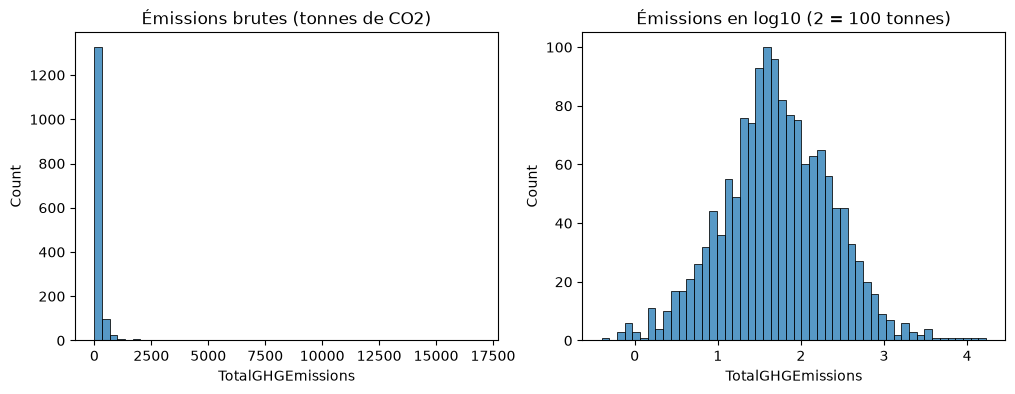

In [17]:
n_avant = len(df)
df = df[df[co2] > 0]
print(f"{n_avant} -> {len(df)} bâtiments ({n_avant - len(df)} retirés)")

print("asymétrie brute :", round(df[co2].skew(), 2))
print("asymétrie en log10 :", round(np.log10(df[co2]).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[co2], bins=50, ax=axes[0])
axes[0].set_title("Émissions brutes (tonnes de CO2)")
sns.histplot(np.log10(df[co2]), bins=50, ax=axes[1])
axes[1].set_title("Émissions en log10 (2 = 100 tonnes)")
plt.show()

Comme pour la consommation, la distribution est très étalée à cause de quelques gros émetteurs. En log10, elle devient presque symétrique, donc le notebook 3 travaillera aussi en log10.

### Outliers de la cible

Je repère les bâtiments en dehors des moustaches du boxplot (plus de 1,5 fois l'écart interquartile au-dessus de Q3 ou en dessous de Q1), sur la consommation en log10.

In [18]:
log_conso = np.log10(df[cible])
q1 = log_conso.quantile(0.25)
q3 = log_conso.quantile(0.75)
ecart = q3 - q1

trop_bas = log_conso < q1 - 1.5 * ecart
trop_haut = log_conso > q3 + 1.5 * ecart
print("trop bas :", trop_bas.sum(), "| trop hauts :", trop_haut.sum())

df[trop_bas | trop_haut]["PrimaryPropertyType"].value_counts()

trop bas : 2 | trop hauts : 9


PrimaryPropertyType
Hospital                 5
Other                    2
Mixed Use Property       1
University               1
Self-Storage Facility    1
Warehouse                1
Name: count, dtype: int64

Il y a 11 bâtiments en dehors des moustaches. 9 consomment beaucoup (surtout des hôpitaux, plus une université et de grands bâtiments mixtes) et 2 consomment très peu (un garde-meuble et un entrepôt).

Ce sont des consommations normales pour ces types de bâtiments, pas des erreurs de saisie, donc je les garde.

### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

#### 1. Période de construction

L'année exacte compte moins que l'époque de construction (les normes d'isolation changent avec le temps). Je découpe en 4 périodes qui ont chacune assez de bâtiments.

In [19]:
def periode(annee):
    if annee < 1950:
        return "avant 1950"
    elif annee < 1980:
        return "1950-1979"
    elif annee < 2000:
        return "1980-1999"
    else:
        return "2000 et après"

df["Periode"] = df["YearBuilt"].apply(periode)
df["Periode"].value_counts()

Periode
1950-1979        494
avant 1950       475
1980-1999        288
2000 et après    222
Name: count, dtype: int64

#### 2. Utilise du gaz / de la vapeur

Les quantités de gaz et de vapeur font partie de la consommation totale, donc les garder reviendrait à donner une partie de la réponse au modèle (fuite de données). Par contre, savoir si le bâtiment est raccordé au gaz ou à la vapeur, ça se sait sans compteur. Je garde donc juste 1 (oui) ou 0 (non).

In [20]:
# 1 = oui, 0 = non
df["UtiliseGaz"] = df["NaturalGas(kBtu)"].apply(lambda x: 1 if x > 0 else 0)
df["UtiliseVapeur"] = df["SteamUse(kBtu)"].apply(lambda x: 1 if x > 0 else 0)

print("part qui utilise du gaz :", round(df["UtiliseGaz"].mean(), 2))
print("part qui utilise de la vapeur :", round(df["UtiliseVapeur"].mean(), 2))

part qui utilise du gaz : 0.71
part qui utilise de la vapeur : 0.07


#### 3. Part de la surface en parking

Un parking consomme peu. À surface égale, un bâtiment avec beaucoup de parking devrait consommer moins.

In [21]:
df["PartParking"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]
df["PartParking"].describe()

count    1479.000000
mean        0.066562
std         0.145182
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.895023
Name: PartParking, dtype: float64

#### 4. Nombre d'usages

Je compte combien d'usages sont renseignés (1, 2 ou 3), pour voir si les bâtiments multi-usages consomment différemment.

In [22]:
df["NbUsages"] = 1 + df["SecondLargestPropertyUseType"].notna().astype(int) + df["ThirdLargestPropertyUseType"].notna().astype(int)
df["NbUsages"].value_counts()

NbUsages
1    675
2    478
3    326
Name: count, dtype: int64

#### 5. Colonnes retirées

Je retire ensuite :
- `YearBuilt`, remplacée par `Periode` ;
- les colonnes d'énergie brutes (fuite de données), remplacées par `UtiliseGaz` et `UtiliseVapeur` ;

`ENERGYSTARScore` reste dans le fichier : il est calculé à partir de la consommation, donc il ne fera pas partie du modèle final, mais je le teste à la fin du notebook de modélisation.

In [23]:
colonnes_a_retirer = [
    "YearBuilt",
    "Electricity(kWh)",
    "Electricity(kBtu)",
    "NaturalGas(therms)",
    "NaturalGas(kBtu)",
    "SteamUse(kBtu)",
]
df = df.drop(columns=colonnes_a_retirer)
print(df.shape)
df.head()

(1479, 21)


,PrimaryPropertyType,Neighborhood,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,...,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,Periode,UtiliseGaz,UtiliseVapeur,PartParking,NbUsages
0,Hotel,DOWNTOWN,1.0,12,88434,0,88434,Hotel,88434.0,NaN,...,NaN,0.0,60.0,7226362.5,249.98,avant 1950,1,1,0.000000,1
1,Hotel,DOWNTOWN,1.0,11,103566,15064,88502,Hotel,83880.0,Parking,...,Restaurant,4622.0,61.0,8387933.0,295.86,1980-1999,1,0,0.145453,3
2,Hotel,DOWNTOWN,1.0,41,956110,196718,759392,Hotel,756493.0,NaN,...,NaN,0.0,43.0,72587024.0,2089.28,1950-1979,1,1,0.205748,1
3,Hotel,DOWNTOWN,1.0,10,61320,0,61320,Hotel,61320.0,NaN,...,NaN,0.0,56.0,6794584.0,286.43,avant 1950,1,1,0.000000,1
4,Hotel,DOWNTOWN,1.0,18,175580,62000,113580,Hotel,123445.0,Parking,...,Swimming Pool,0.0,75.0,14172606.0,505.01,1980-1999,1,0,0.353115,3


### Préparation des features

#### 1. Matrice de corrélation

Si deux colonnes sont très corrélées (au-dessus de 0,9), elles disent presque la même chose et on peut en enlever une.

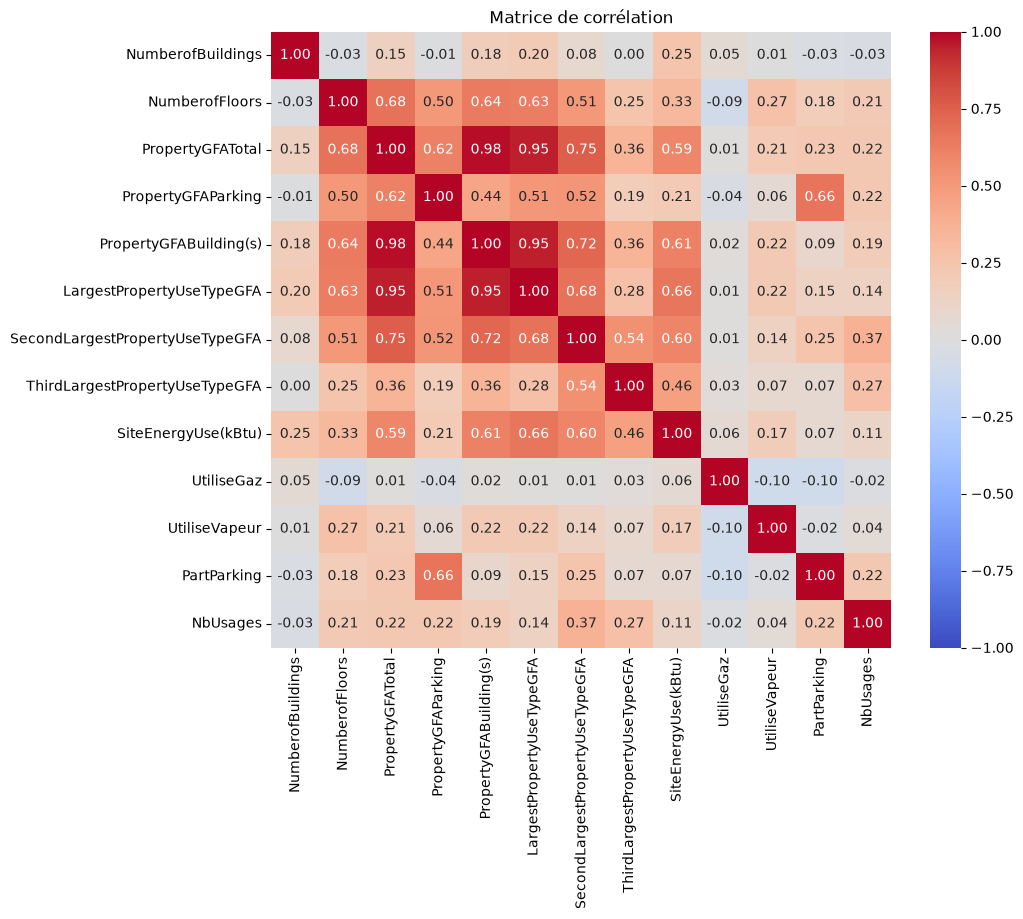

In [24]:
# corrélation de Pearson entre les colonnes numériques (cible comprise)
# sans le CO2 et l'ENERGY STAR Score, qui ne serviront pas de features
corr = df.select_dtypes("number").drop(columns=["TotalGHGEmissions", "ENERGYSTARScore"]).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

`PropertyGFATotal`, `PropertyGFABuilding(s)` et `LargestPropertyUseTypeGFA` sont corrélées entre 0,95 et 0,98. C'est logique, c'est quasiment la même surface comptée de trois façons. Le reste est en dessous de 0,8 (par exemple 0,68 entre le nombre d'étages et la surface totale).

Je garde `PropertyGFATotal`, la plus simple à expliquer (et c'est celle que j'ai utilisée pour calculer `PartParking`).

In [25]:
df = df.drop(columns=["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA"])
print(df.shape)

(1479, 19)


#### 2. Lien entre les features et la cible

Le boxplot par type de bâtiment est fait plus haut, je regarde ici la surface, la période de construction et la vapeur.

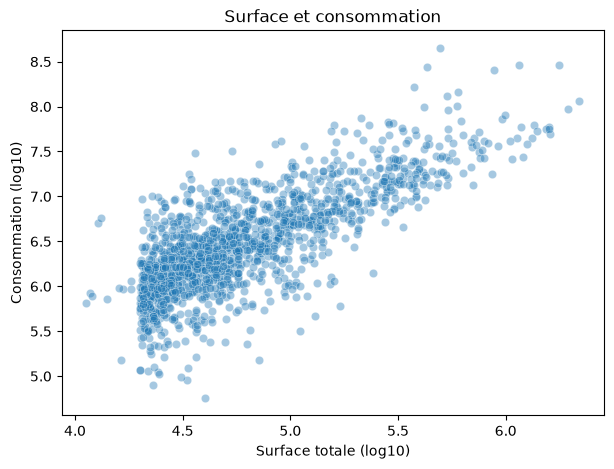

corrélation : 0.77


In [26]:
# surface et consommation en log10, sinon les très grands bâtiments écrasent le graphique
plt.figure(figsize=(7, 5))
sns.scatterplot(x=np.log10(df["PropertyGFATotal"]), y=log_conso, alpha=0.4)
plt.xlabel("Surface totale (log10)")
plt.ylabel("Consommation (log10)")
plt.title("Surface et consommation")
plt.show()

print("corrélation :", round(np.corrcoef(np.log10(df["PropertyGFATotal"]), log_conso)[0, 1], 2))

Les points sont presque alignés : plus le bâtiment est grand, plus il consomme. La surface devrait être la variable la plus utile pour le modèle.

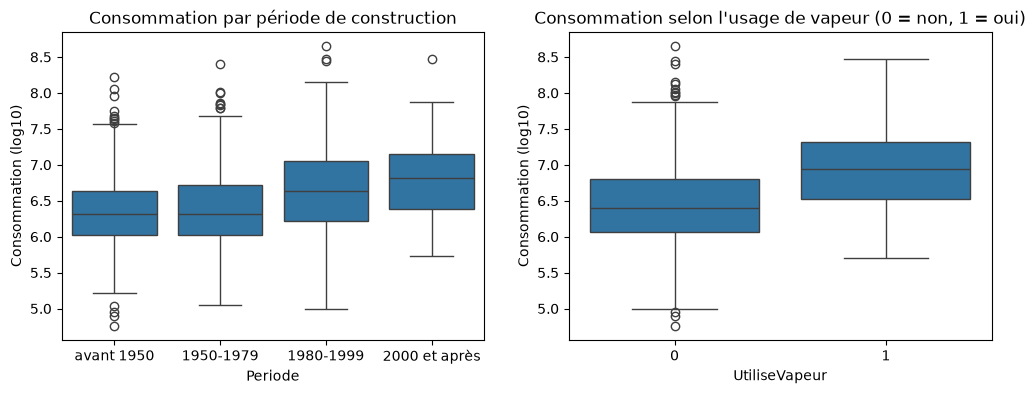

In [27]:
ordre = ["avant 1950", "1950-1979", "1980-1999", "2000 et après"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Periode"], y=log_conso, order=ordre, ax=axes[0])
axes[0].set_title("Consommation par période de construction")
axes[0].set_ylabel("Consommation (log10)")

sns.boxplot(x=df["UtiliseVapeur"], y=log_conso, ax=axes[1])
axes[1].set_title("Consommation selon l'usage de vapeur (0 = non, 1 = oui)")
axes[1].set_ylabel("Consommation (log10)")
plt.show()

Pour la période, c'est l'inverse de ce que j'attendais : les bâtiments récents consomment plus (médiane autour de 6,3 avant 1980 et de 6,8 après 2000). Je pense que ce n'est pas un problème d'isolation, mais plutôt que les bâtiments récents sont plus grands.

Pour la vapeur, les bâtiments raccordés consomment environ 3,5 fois plus (médiane 6,9 contre 6,4). Ce sont surtout les gros bâtiments du centre-ville reliés au réseau de chaleur.

Pour le gaz, l'écart est très faible (6,4 dans les deux cas), donc je n'ai pas fait de graphique.

#### 3. Nettoyage des colonnes texte

Je corrige deux choses dans les colonnes texte. Les quartiers sont parfois en majuscules et parfois non (`NORTH` et `North`), donc je mets tout en majuscules. Et quand il n'y a pas de 2e ou 3e usage, je mets « Aucun » à la place de la case vide.

In [28]:
df["Neighborhood"] = df["Neighborhood"].str.upper().replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")
print("quartiers :", df["Neighborhood"].nunique())

usages = ["LargestPropertyUseType", "SecondLargestPropertyUseType", "ThirdLargestPropertyUseType"]
df[usages] = df[usages].fillna("Aucun")

quartiers : 13


#### 4. Surfaces en log10

Les surfaces sont très étalées, comme la cible, donc je les passe en log10. J'ajoute 1 avant le log parce que les parkings et les 2e/3e usages peuvent valoir 0 m².

In [29]:
surfaces = ["PropertyGFATotal", "PropertyGFAParking", "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]
for col in surfaces:
    df[col] = np.log10(df[col] + 1)

df[surfaces].describe().round(2)

,PropertyGFATotal,PropertyGFAParking,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA
count,1479.00,1479.00,1479.00,1479.00
mean,4.79,0.99,2.07,0.78
std,0.42,1.89,2.14,1.56
min,4.05,0.00,0.00,0.00
25%,4.46,0.00,0.00,0.00
50%,4.68,0.00,0.00,0.00
75%,5.02,0.00,4.13,0.00
max,6.34,5.71,5.81,5.66


### Colonnes gardées pour la modélisation

In [30]:
# colonnes envoyées au notebook de modélisation
print(df.shape)
df.columns.tolist()

(1479, 19)


['PrimaryPropertyType',
 'Neighborhood',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'PropertyGFAParking',
 'LargestPropertyUseType',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'ENERGYSTARScore',
 'SiteEnergyUse(kBtu)',
 'TotalGHGEmissions',
 'Periode',
 'UtiliseGaz',
 'UtiliseVapeur',
 'PartParking',
 'NbUsages']

| Rôle | Colonnes |
|---|---|
| **Cibles** (une par notebook de modélisation) | `SiteEnergyUse(kBtu)` (notebook 2), `TotalGHGEmissions` (notebook 3) |
| **Infos de la fiche** (connues sans mesurer) | type et usages : `PrimaryPropertyType`, `LargestPropertyUseType`, `SecondLargestPropertyUseType`, `ThirdLargestPropertyUseType`<br>quartier : `Neighborhood`<br>surfaces (en log10) : `PropertyGFATotal`, `PropertyGFAParking`, `SecondLargestPropertyUseTypeGFA`, `ThirdLargestPropertyUseTypeGFA`<br>taille : `NumberofFloors`, `NumberofBuildings` |
| **Créées au feature engineering** | `Periode`, `UtiliseGaz`, `UtiliseVapeur`, `PartParking`, `NbUsages` |
| **Gardée pour un test** (pas dans le modèle final) | `ENERGYSTARScore` |

### Sauvegarde pour les notebooks de modélisation

In [31]:
df.to_csv("data/batiments_cible.csv", index=False)
print(df.shape)

(1479, 19)
